# Stellar rotation from a NEMESIS light curve: TIC 350545089

TIC **350545089** (2MASS J12394672+0410471), a known [MEarth rotator](https://lweb.cfa.harvard.edu/MEarth/DataDR11.html). The
showcase cites a rotation period near **4.1 days** and found a
Lomb–Scargle peak near **4.143 days** using TESS 30-minute FFI data.

Unlike the TOI-1235 transit tutorial, this example turns **off** BLS/TLS
searches and works with NEMESIS **PLD Flux**, preserving modulation that
planet-search detrending might suppress. We use Sector 23, shown in the
showcase output, instead of fetching all observed sectors.

Requires MAST/TESScut access only for the download cell; analysis can be
repeated using the saved CSV.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.timeseries import LombScargle
from nemesis_tess import full_pipeline, default_NEMESIS_pipeline_settings

TIC_ID, SECTOR = 350545089, 23
output = Path.home() / 'nemesis_tutorials' / 'rotation_tic350545089_s23'
output.mkdir(parents=True, exist_ok=True)

# RUN_DOWNLOAD = False  # set True to fetch the FFI light curve
RUN_DOWNLOAD = True  # set True to fetch the FFI light curve
if RUN_DOWNLOAD:
    settings = default_NEMESIS_pipeline_settings()
    settings['do_transit_search'] = False
    settings['get_all_sectors'] = False
    hdu, lc_df, transit_results, run_settings = full_pipeline(
        ID=TIC_ID, path=str(output) + '/', Sector=SECTOR,
        cadence='30 minute', settings=settings,
    )
    assert lc_df is not None and not lc_df.empty
    assert transit_results is None  # intentionally disabled

lc_path = (output / f'Sector_{SECTOR:04d}' / 'NEMESIS_FFI_LCs' /
           f'TIC_{TIC_ID}_Sector_{SECTOR:04d}_final_LC.csv')
if not lc_path.exists():
    raise FileNotFoundError(
        f'Missing {lc_path}. Set RUN_DOWNLOAD=True for the first run.')
lc_df = pd.read_csv(lc_path)
print('Available columns:', lc_df.columns.tolist())

[get_qdata] Downloading: https://archive.stsci.edu/missions/tess/engineering/tess2020107160812_sector23-quat.fits
[prefetch_quaternions] 1/1 sectors ready.
TIC 350545089  Sector 23 ; Now creating Light Curve


[identity] TIC 350545089 S23: verified /Users/daxfeliz/nemesis_tutorials/rotation_tic350545089_s23/cache/TESSCut/tess-s0023-1-3_189.944733_4.179791_11x11_astrocut.fits (sep 0.00 arcsec, position from header)
gethdu TESScut queries took: 8.565 seconds 

gethdu took: 8.573 seconds 


TIC 350545089  Sector 23
  CCD=3  Camera=1  hdu type=HDUList
  [REFPIX DIAG] S23: reference_pixel = col=5.001, row=5.001
  [REFPIX DIAG] S23: WCS(RA,Dec)->pix = col=5.710, row=5.526
  [REFPIX DIAG] S23: offset = col:-0.708, row:-0.525
get_LC_from_FFI hdu type check: <class 'astropy.io.fits.hdu.hdulist.HDUList'> ; [<astropy.io.fits.hdu.image.PrimaryHDU object at 0x3449b1370>, <astropy.io.fits.hdu.table.BinTableHDU object at 0x3448cbc20>, <astropy.io.fits.hdu.image.ImageHDU object at 0x3448cab10>]
[get_qdata] Using cached: /Users/daxfeliz/nemesis_tutorials/rotation_tic350545089_s23/cache/quaternions/sector_23_quaternion.fits


savelcpath: /Users/daxfeliz/nemesis_tutorials/rotation_tic350545089_s23/Sector_0023/NEMESIS_FFI_LCs/
check_centroids: /Users/daxfeliz/nemesis_tutorials/rotation_tic350545089_s23/Sector_0023/NEMESIS_FFI_LCs/ TIC_350545089_Sector_0023_pix_mask

NEMESIS Light Curve production took: 13.852 seconds 



 
NEMESIS Pipeline took: 33.788 seconds 

Available columns: ['CADENCE_INDEX', 'Time', 'RAW SAP Flux', 'SAP Flux', 'SAP Error', 'QUALITY_FLAG', 'Background Flux', 'Background Error', 'PLD Flux', 'PLD Error', 'PLD Model', 'Detrended Flux', 'Detrended Error', 'Fitted Trend', 'Centroid X Positions', 'Centroid Y Positions', 'QUALITY_FLAGS']


In [3]:
# Reproduce the light-curve choice in the PDF rather than using the
# potentially high-pass-filtered planet-search 'Detrended Flux'.
from nemesis_tess.pipeline import pd_to_lk
lc = pd_to_lk(lc_df, flux_type='PLD')

# Analysis uses Astropy's LombScargle directly on the PLD data.
time = np.asarray(lc.time.value, dtype=float)
flux = np.asarray(lc.flux.value, dtype=float)
valid = np.isfinite(time) & np.isfinite(flux)
time, flux = time[valid], flux[valid]
flux = flux / np.median(flux)

baseline = float(np.ptp(time))
min_period = 0.1  # days, as in the showcase
max_period = baseline / 3.0  # showcase's upper-period choice
assert 0 < min_period < max_period
ls = LombScargle(time, flux, center_data=True)
frequency, power = ls.autopower(
    minimum_frequency=1.0 / max_period,
    maximum_frequency=1.0 / min_period,
    samples_per_peak=10,
)
period = 1.0 / frequency
best_period = float(period[np.argmax(power)])
print(f'Highest LS peak: {best_period:.5f} d')
print('Showcase reference: 4.14311 d; compare aliases before identification.')

Highest LS peak: 4.14311 d
Showcase reference: 4.14311 d; compare aliases before identification.


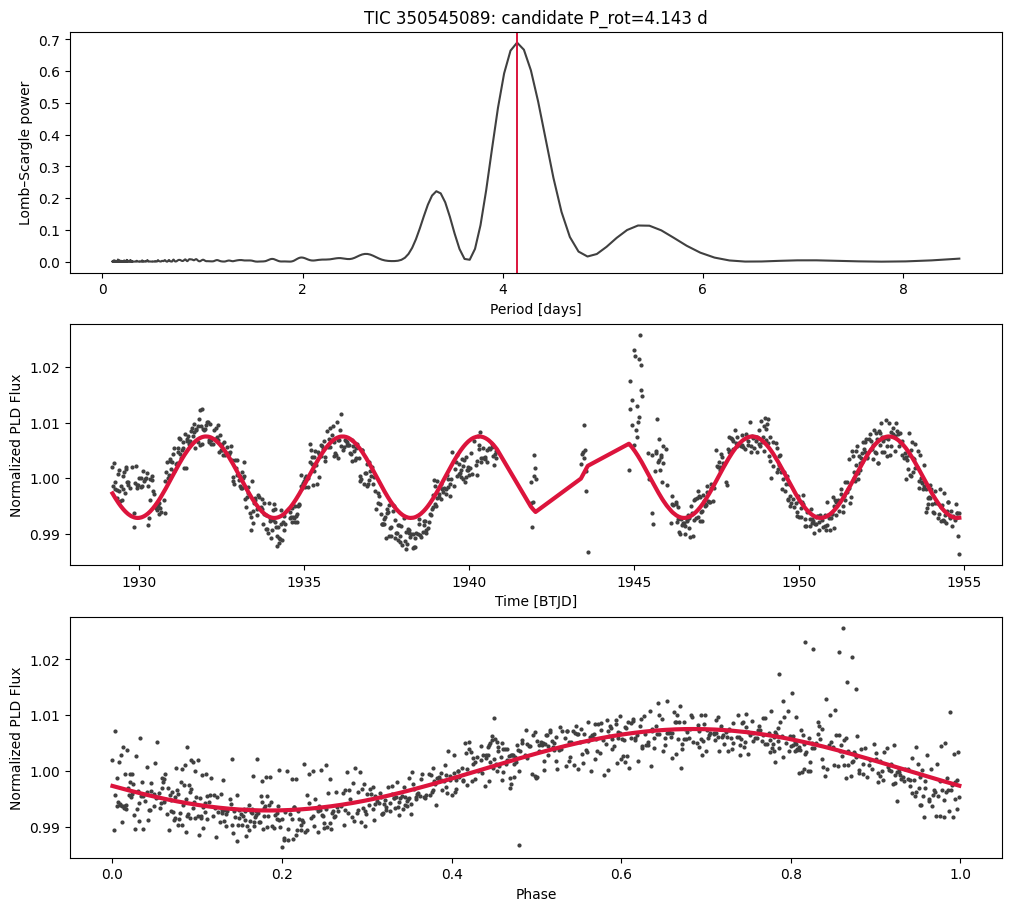

In [6]:
# Three panels: periodogram, time-series with LS model, phase fold.
model = ls.model(time, 1.0 / best_period)
phase = ((time - time.min()) / best_period) % 1.0

fig, axes = plt.subplots(3, 1, figsize=(10, 9), layout='constrained')
axes[0].plot(period, power, color='0.25')
axes[0].axvline(best_period, color='crimson', lw=1.4)
axes[0].set(xlabel='Period [days]', ylabel='Lomb–Scargle power',
            title=f'TIC {TIC_ID}: candidate P_rot={best_period:.3f} d')
axes[1].scatter(time, flux, c='0.25', s=4)
axes[1].plot(time, model, color='crimson', lw=3)
axes[1].set(xlabel='Time [BTJD]', ylabel='Normalized PLD Flux')
axes[2].scatter(phase, flux, c='0.25', s=4)
order = np.argsort(phase)
axes[2].plot(phase[order], model[order], color='crimson', lw=3)
axes[2].set(xlabel='Phase', ylabel='Normalized PLD Flux')
plt.show()

**Interpretation:** Your reference screenshot (p. 6) shows a periodogram peak
near 4.143 days, but this is not a guaranteed recovery threshold on every
reduction: inspect harmonics, spacecraft-period aliases, PLD systematics and
sector-to-sector agreement. The reference cited in the showcase is Newton et al. (2015).